# 01 — Exploratory Data Analysis

Egyptian sentiment data (ASTD + ArSarcasm-v2 Egyptian subset) after `src.data.unify` and `src.data.split`.

Arabic text is shown in tables, not plots (matplotlib can't shape Arabic script).

In [1]:
import json, os, re
from collections import Counter
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from src.preprocess import preprocess, tokenize

pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid")
PLOTS = Path("results/plots"); PLOTS.mkdir(parents=True, exist_ok=True)
LABEL_ORDER = ["negative", "neutral", "positive"]

all_df = pd.read_csv("data/processed/all.csv")
splits = {s: pd.read_csv(f"data/processed/{s}.csv") for s in ["train", "val", "test"]}
stats = json.loads(Path("data/processed/split_stats.json").read_text())
print(f"all: {len(all_df):,} rows | " + " | ".join(f"{k}: {len(v):,}" for k, v in splits.items()))

all: 11,408 rows | train: 4,849 | val: 1,141 | test: 1,141


## 1. Label distribution

Neutral is capped to the negative count in **train only**; val/test keep the natural distribution.

In [2]:
rows = []
for stage in ["before_cap", "after_cap"]:
    for split, counts in stats[stage].items():
        for label, n in counts.items():
            rows.append({"stage": stage, "split": split, "label": label, "n": n})
counts = pd.DataFrame(rows)
table = counts.pivot_table(index=["stage", "split"], columns="label", values="n").reindex(columns=LABEL_ORDER)
table["total"] = table.sum(axis=1)
display(table.astype(int))
display((table[LABEL_ORDER].div(table["total"], axis=0) * 100).round(1).rename(columns=lambda c: c + " %"))

label             negative  neutral  positive  total
stage      split                                    
after_cap  test        249      786       106   1141
           train      2001     2001       847   4849
           val         251      785       105   1141
before_cap test        249      786       106   1141
           train      2001     6278       847   9126
           val         251      785       105   1141

label             negative %  neutral %  positive %
stage      split                                   
after_cap  test         21.8       68.9         9.3
           train        41.3       41.3        17.5
           val          22.0       68.8         9.2
before_cap test         21.8       68.9         9.3
           train        21.9       68.8         9.3
           val          22.0       68.8         9.2

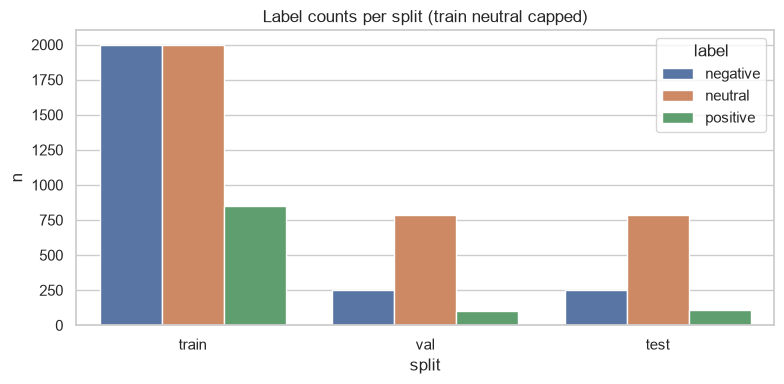

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
plot_df = counts[(counts.stage == "after_cap")]
sns.barplot(data=plot_df, x="split", y="n", hue="label", hue_order=LABEL_ORDER, ax=ax)
ax.set_title("Label counts per split (train neutral capped)")
fig.tight_layout(); fig.savefig(PLOTS / "eda_label_counts.png", dpi=150)

## 2. Sources

`arsarcasm|astd` = the same tweet appeared in both datasets with the same label (kept once). Conflicting duplicates were dropped in `unify`.

In [4]:
display(pd.crosstab(all_df["source"], all_df["label"], margins=True)[LABEL_ORDER + ["All"]])

label,negative,neutral,positive,All
source,,,,
arsarcasm,896,721,306,1923
arsarcasm|astd,475,68,156,699
astd,1130,7060,596,8786
All,2501,7849,1058,11408


## 3. Text length (tokens after full preprocessing)

Used to choose `max_len` for the LSTM (planned 64).

In [5]:
all_df["clean"] = all_df["text"].map(preprocess)
all_df["n_tokens"] = all_df["clean"].map(lambda t: len(tokenize(t)))
display(all_df.groupby("label")["n_tokens"].describe(percentiles=[.5, .9, .95, .99]).round(1))
print("share of texts longer than 64 tokens:", round((all_df.n_tokens > 64).mean() * 100, 2), "%")

,count,mean,std,min,50%,90%,95%,99%,max
label,,,,,,,,,
negative,2501.0,18.7,8.1,1.0,19.0,26.0,29.0,50.0,65.0
neutral,7849.0,15.6,6.5,1.0,16.0,24.0,26.0,29.0,68.0
positive,1058.0,15.4,7.5,1.0,15.5,25.0,27.0,31.0,52.0


share of texts longer than 64 tokens: 0.03 %


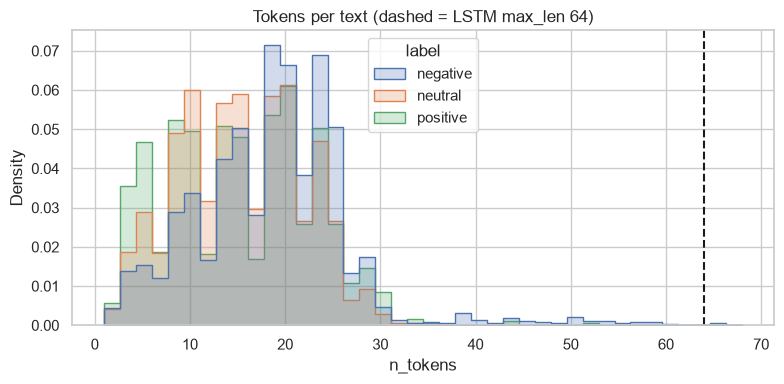

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=all_df, x="n_tokens", hue="label", hue_order=LABEL_ORDER, bins=40, element="step", stat="density", common_norm=False, ax=ax)
ax.axvline(64, ls="--", c="k"); ax.set_title("Tokens per text (dashed = LSTM max_len 64)")
fig.tight_layout(); fig.savefig(PLOTS / "eda_lengths.png", dpi=150)

## 4. Vocabulary

Tokens in val/test that never appear in train are invisible to the embedding models (M2, M3) — a first hint at how hard dialect generalization is.

In [7]:
tok = {s: [t for x in df["text"] for t in tokenize(preprocess(x))] for s, df in splits.items()}
train_vocab = Counter(tok["train"])
print(f"train vocab: {len(train_vocab):,} types | {sum(train_vocab.values()):,} tokens")
print(f"types seen >= 2 times: {sum(1 for c in train_vocab.values() if c >= 2):,}")
for s in ["val", "test"]:
    oov = sum(1 for t in tok[s] if t not in train_vocab) / len(tok[s])
    print(f"{s} token OOV rate vs train: {oov:.1%}")

train vocab: 23,118 types | 81,688 tokens
types seen >= 2 times: 7,750
val token OOV rate vs train: 18.9%
test token OOV rate vs train: 19.5%


## 5. Most distinctive tokens per class

Ranked by smoothed log-odds of a token appearing in that class vs the others (train split, min count 5).

In [8]:
import math
train = splits["train"].assign(toks=splits["train"]["text"].map(lambda x: tokenize(preprocess(x))))
by_label = {l: Counter(t for ts in train.loc[train.label == l, "toks"] for t in ts) for l in LABEL_ORDER}
total = Counter(); [total.update(c) for c in by_label.values()]
rows = {}
for l, c in by_label.items():
    rest = total - c
    n_c, n_r = sum(c.values()), sum(rest.values())
    scores = {t: math.log((c[t] + 1) / (n_c + len(total))) - math.log((rest[t] + 1) / (n_r + len(total)))
              for t in c if total[t] >= 5}
    rows[l] = [t for t, _ in sorted(scores.items(), key=lambda kv: -kv[1])[:20]]
display(pd.DataFrame(rows))

,negative,neutral,positive
0,عار,الوفد,☆
1,اعلام,ذات,❤
2,كذب,بعنوان,احبك
3,الخرفان,نيوز,😘
4,فاشل,البوابه,بتحبه
5,العار,للدكتور,بحبك
6,عميل,اجتماع,عياش
7,مسخره,صانع,امير
8,معاهم,جدو,😍
9,كلب,حمزاوي,رائعه


## 6. Emojis per class

In [9]:
emoji_re = re.compile(r"[\U0001F300-\U0001FAFF\u2600-\u27BF]")
train["emojis"] = train["text"].map(emoji_re.findall)
print("train texts with >=1 emoji:", f"{(train.emojis.str.len() > 0).mean():.1%}")
display(pd.DataFrame({l: [f"{e} ({n})" for e, n in Counter(e for es in train.loc[train.label == l, "emojis"] for e in es).most_common(10)]
                      for l in LABEL_ORDER}))

train texts with >=1 emoji: 6.0%


,negative,neutral,positive
0,😂 (100),😂 (35),😂 (159)
1,💔 (13),❤ (10),❤ (34)
2,👌 (7),👏 (8),😍 (33)
3,😁 (7),♡ (7),☆ (24)
4,😭 (7),💃 (7),♡ (12)
5,🏻 (5),😍 (4),😭 (8)
6,😎 (4),☺ (4),♥ (7)
7,😅 (4),😒 (3),👏 (7)
8,🔫 (4),👌 (2),💙 (6)
9,😔 (4),😕 (2),👌 (6)


## 7. Random samples per class

In [10]:
for l in LABEL_ORDER:
    print(f"--- {l} ---")
    for t in splits["train"].loc[splits["train"].label == l, "text"].sample(5, random_state=0):
        print("  ", t)

--- negative ---
   _ قمع الثورة في البحرين بطريقة همجية جريمة تم التغاضى عنها لاسباب طائفية الانسان يجب ان يتمتع بحقوقه مهما يكن دينه او مذهبه
   من قال أن دستور الجماعة لا يقسم مصر يجب أن يكشف على نظره فهذا شيء واضح وضوح الشمس
   هاتسبني تفضل سبني من غير ما تهديدني عمرك متعوضني ~~اناقلبي هايوجعني #اليسابستغرب انا الغنية دي وايد البدايه قويه والنهايه ضعيف
   @mnaw7 @ethraaen  ههههههه جبهة النصرة وداعش  ممثلين ل هولاكو
   د أبو الفتوح : رقابة الدولة على الأفكار يحول الناس الى مؤمنين منافقين وهذا ما لانريده ولا نقبله
--- neutral ---
   #غرد_بالخير #غرد_بصورة #شبكة_المجد "
   #وزير_التموين : توفير كافة السلع بأسعار مخفضة 15% في "المجمعات الاستهلاكية"
   الآن النشيد الوطني
   ليت الليالي تجيب الي على بالي واشوف زوله بعد ما طول الغيبه ان كان ماعاد له جيه بري حالي يمكن على عز هذا العمر اهذريبه #عادل
   مقال النقاب على موقع الشروق وفي كتابي مصر على دكة الاحتياطي ليس هذا موضوعنا الان اردت فقط ان ابين كيف يسلك الفاشيون عندما تختلف معهم
--- positive ---
   بعد رفض ضياء رشوان (قطة النظام) تعديلا

## Takeaways

1. **Class balance.** Train is 41/41/18 (neg/neu/pos) after capping; val/test are ~22/69/9. Positive is the scarcest class (847 train, ~105 test) → expect the weakest per-class F1 there; macro-F1 is the headline metric because accuracy is inflated by neutral.
2. **Length.** Texts are short (median 15–19 tokens, 99th pct ≤ 50). `max_len=64` for the LSTM truncates ~0.03% of texts. 128 subwords is ample for the transformers.
3. **Vocabulary / OOV.** ~20% of val/test tokens are unseen in train, so word-level models (M2, M3) lean heavily on pretrained AraVec vectors; char n-grams in M1 should help with spelling variation.
4. **Topic bias.** The data is mostly 2013–2015 Egyptian political/news tweets. Distinctive tokens include politics and news words for neutral/negative and a TV personality's name for positive, which are spurious cues. Our custom test set (restaurants, products, football, everyday speech) is therefore *out-of-domain* as well as dialect-focused; interpret drops with that in mind.
5. **Not purely Egyptian.** Many "Egyptian" tweets are news-style MSA. The dialect signal in training is weaker than the source label suggests, which is part of what the MSA-vs-dialect comparison will reveal.
6. **Emojis.** Only ~6% of tweets have one, and 😂 is the top emoji in *both* positive and negative (sarcasm/mockery), so emojis alone are not reliable sentiment cues.
7. **Label noise.** Random samples include news headlines labeled positive, and 330 texts had conflicting labels between ASTD and ArSarcasm. Expect a noise ceiling on in-domain scores.
